# Test set

**Summary** (239 test queries, used once; every choice was made on the 241 dev queries)
- **Hybrid search holds:** BM25 + inf-1.5B + arctic-m beats inf-1.5B alone by +1.9 nDCG@10 (p = 0.002), as on dev (+2.1).
- **Expansion still helps BM25 a lot:** 151 of the 161 combinations chosen on dev are significantly better on test.
- **Expansion on top of the hybrid does not improve the top 10 on test:** +0.1 to +0.8 nDCG@10, none significant, against +0.9 to +1.4 on dev. The dev gain was partly luck from picking the best of many combinations.
- **It does improve recall:** all 14 combinations find significantly more Exact products in the top 100 (+0.8 to +2.2 Rcap@100), which on dev was too small to show.
- Test queries score 2–3 points higher than dev for every system, so compare systems within a split, not across splits.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from product_search.data.splits import load_split
from product_search.data.wands import label_grades, load_wands
from product_search.eval.metrics import per_query_metrics
from product_search.eval.stats import paired_permutation_test
from product_search.retrieval.fusion import rrf
from product_search.runs import RUNS_DIR, load_results

Q_RULE = 0.05
METRICS = {"nDCG@10": "nDCG@10", "Rcap@100_exact": "Rcap@100"}
RUNS = {"BM25": "bm25_default", "inf-1.5B": "dense_inf_15b", "arctic-m": "dense_arctic_m"}
GRID = "expansion_grid_qwen3_0.6b"
KEYS = ["mode", "system", "products", "queries"]
NAMES = {
    "p1_t5all": "P1 all-T5",
    "p1_qwen": "P1 Qwen",
    "p2": "P2",
    "p3": "P3",
    "q1": "Q1",
    "q2": "Q2",
    "q3": "Q3",
    "q4": "Q4",
}
GREEN, RED = "#d6f0d6", "#f7d4d4"
DEV, TEST = ("#eb6834", "s"), ("#2a78d6", "o")

split = load_split()
labels = label_grades(load_wands().labels)
grids = {
    "dev": pd.read_csv(RUNS_DIR / GRID / "grid.csv"),
    "test": pd.read_csv(RUNS_DIR / f"{GRID}_test" / "grid.csv"),
}


def combo(keys: str) -> str:
    """'p1_qwen+p2' -> 'P1 Qwen + P2'."""
    return " + ".join(NAMES[k] for k in keys.split("+"))


def per_query(side: str) -> dict[str, pd.DataFrame]:
    """Per-query metrics of each base system on one side of the split."""
    suffix = "" if side == "dev" else "_test"
    query_ids = getattr(split, side)
    runs = {
        name: load_results(RUNS_DIR / f"{run}{suffix}" / "results.parquet")
        for name, run in RUNS.items()
    }
    runs["hybrid"] = rrf(list(runs.values()))
    return {
        name: per_query_metrics(results, labels, query_ids)[list(METRICS)]
        for name, results in runs.items()
    }


base = {side: per_query(side) for side in ("dev", "test")}

## 1. What was run

Fixed on dev before test was opened: BM25 (default settings), inf-1.5B, arctic-m, their RRF hybrid, and every expansion combination that was significantly better on dev with Qwen3-0.6B query expansion, separate mode (177 rows: 161 BM25, 2 dense, 14 hybrid). Q4 was generated for the test queries from the test first stage; nothing else was regenerated. The q-values on test adjust for these 177 tests.

## 2. The base systems

In [2]:
table = pd.DataFrame(
    {
        (label, side): {name: frame[metric].mean() for name, frame in base[side].items()}
        for metric, label in METRICS.items()
        for side in ("dev", "test")
    }
)
display(table.style.format("{:.3f}"))

**Table 1. Each base system on dev and on test.** **Test is higher for every system** (nDCG@10 +2 to +3 points), so the test queries are somewhat easier; the order of the systems is the same, and the hybrid is best on both splits.

## 3. Expansion on top of the hybrid

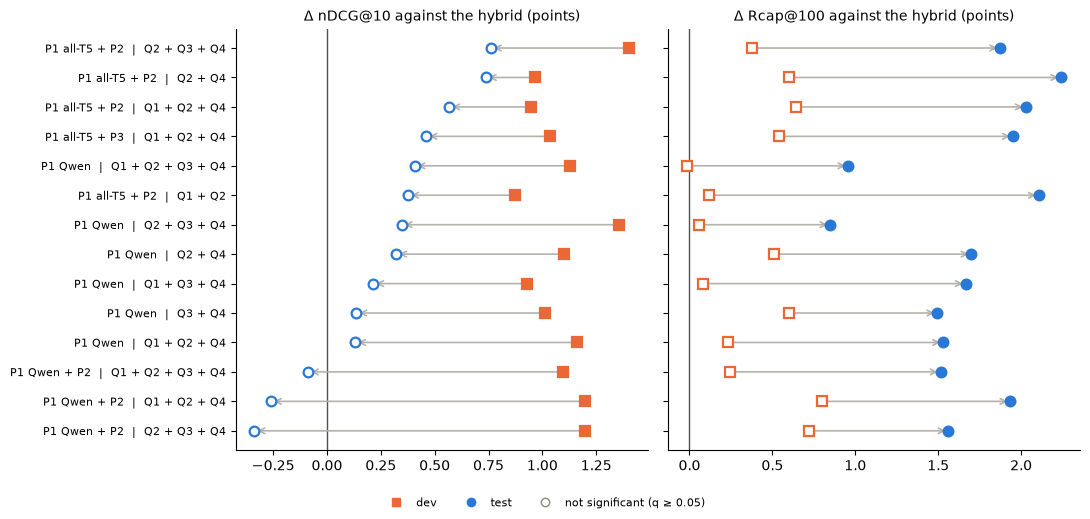

In [3]:
hybrid = {side: grid[(grid.system == "hybrid")].set_index(KEYS[1:]) for side, grid in grids.items()}
rows = hybrid["dev"].index.intersection(hybrid["test"].index)
order = hybrid["test"].loc[rows].sort_values("Δ nDCG@10").index
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
for ax, (metric, label) in zip(axes, METRICS.items(), strict=True):
    for y, key in enumerate(order):
        dev_row, test_row = hybrid["dev"].loc[key], hybrid["test"].loc[key]
        ax.annotate(
            "",
            xy=(test_row[f"Δ {metric}"], y),
            xytext=(dev_row[f"Δ {metric}"], y),
            arrowprops={"arrowstyle": "->", "color": "#b4b2a9", "lw": 1.2},
        )
        for row, (colour, marker) in ((dev_row, DEV), (test_row, TEST)):
            significant = row[f"q {metric}"] < Q_RULE
            ax.plot(
                row[f"Δ {metric}"],
                y,
                marker,
                color=colour if significant else "white",
                markeredgecolor=colour,
                markeredgewidth=1.6,
                markersize=7,
                zorder=3,
            )
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_title(f"Δ {label} against the hybrid (points)", fontsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_yticks(
    range(len(order)), [f"{combo(p)}  |  {combo(q)}" for _, p, q in order], fontsize=8
)
axes[0].plot([], [], DEV[1], color=DEV[0], label="dev")
axes[0].plot([], [], TEST[1], color=TEST[0], label="test")
axes[0].plot(
    [], [], "o", color="white", markeredgecolor="#888780", label="not significant (q ≥ 0.05)"
)
fig.legend(fontsize=8, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Figure 1. The 14 hybrid combinations chosen on dev, from dev (orange squares) to test (blue circles).** Filled: q < 0.05; hollow: not significant. Left: **the top-10 gain shrinks on test and is never significant.** Right: **the recall gain grows on test and is significant for every combination.** All are separate-mode lists: P1 plus query expansion (13 of 14 include Q4), queries by Qwen3-0.6B.

## 4. Which findings hold

In [4]:
def compare(side: str, a: str, b: str, metric: str = "nDCG@10") -> tuple[float, float]:
    """Δ (points) and p of system b against system a."""
    diff, p = paired_permutation_test(base[side][a][metric], base[side][b][metric])
    return diff * 100, p


def share_better(side: str, system: str, metric: str) -> tuple[int, int]:
    """Rows of a system significantly better on one side, out of the rows scored on test."""
    grid = grids[side].set_index(KEYS)
    chosen = grids["test"][grids["test"].system == system].set_index(KEYS)
    rows = grid.loc[grid.index.intersection(chosen.index)]
    return int(((rows[f"q {metric}"] < Q_RULE) & (rows[f"Δ {metric}"] > 0)).sum()), len(rows)


def pair(side: str, a: str, b: str) -> str:
    diff, p = compare(side, a, b)
    return f"{diff:+.1f} (p {'< 0.001' if p < 0.001 else f'= {p:.3f}'})"


def count(side: str, system: str, metric: str) -> str:
    better, total = share_better(side, system, metric)
    return f"{better} of {total}"


claims = pd.DataFrame(
    [
        (
            "inf-1.5B beats BM25 (nDCG@10)",
            pair("dev", "BM25", "inf-1.5B"),
            pair("test", "BM25", "inf-1.5B"),
        ),
        (
            "Hybrid beats inf-1.5B (nDCG@10)",
            pair("dev", "inf-1.5B", "hybrid"),
            pair("test", "inf-1.5B", "hybrid"),
        ),
        (
            "Expansion helps BM25 (nDCG@10)",
            count("dev", "bm25", "nDCG@10"),
            count("test", "bm25", "nDCG@10"),
        ),
        (
            "Expansion helps the hybrid's top 10 (nDCG@10)",
            count("dev", "hybrid", "nDCG@10"),
            count("test", "hybrid", "nDCG@10"),
        ),
        (
            "Expansion helps the hybrid's recall (Rcap@100)",
            count("dev", "hybrid", "Rcap@100_exact"),
            count("test", "hybrid", "Rcap@100_exact"),
        ),
    ],
    columns=["finding", "dev", "test"],
).set_index("finding")
claims["holds on test"] = ["✓", "✓", "✓", "✗", "✓ (new)"]
display(
    claims.style.map(
        lambda v: f"background-color: {GREEN if v.startswith('✓') else RED}",
        subset=["holds on test"],
    )
)

,dev,test,holds on test
finding,,,
inf-1.5B beats BM25 (nDCG@10),+6.8 (p < 0.001),+7.6 (p < 0.001),✓
Hybrid beats inf-1.5B (nDCG@10),+2.1 (p = 0.004),+1.9 (p = 0.002),✓
Expansion helps BM25 (nDCG@10),161 of 161,151 of 161,✓
Expansion helps the hybrid's top 10 (nDCG@10),14 of 14,0 of 14,✗
Expansion helps the hybrid's recall (Rcap@100),0 of 14,14 of 14,✓ (new)


**Table 2. Dev against test.** Pairs: change in points and paired permutation p. Counts: combinations significantly better (q < 0.05) out of those chosen on dev. **Everything holds except the top-10 gain from expansion on the hybrid**, which turns into a recall gain.

**Conclusion.** The reliable result is the hybrid: +1.9 nDCG@10 over the best single model on test, for 37 ms. Expansion is a large win for BM25 alone, but on top of the hybrid ~470 ms of LLM expansion buys about +1 to +2 points of recall in the top 100, not a better top 10. Choosing the best of hundreds of combinations on 241 queries overstated its dev gain; this is why the test set was kept until now.